In [1]:
# Provides ways to work with large multidimensional arrays
import numpy as np 
# Allows for further data manipulation and analysis
import pandas as pd 
import matplotlib.pyplot as plt # Plotting
import matplotlib.dates as mdates # Styling dates
%matplotlib inline

# pip install numpy
# conda install -c anaconda pandas
# conda install -c conda-forge matplotlib

import datetime as dt # For defining dates

import time

# In Powershell Prompt : conda install -c conda-forge multitasking
# pip install -i https://pypi.anaconda.org/ranaroussi/simple yfinance

import yfinance as yf

# To show all your output File -> Preferences -> Settings Search for Notebook
# Notebook Output Text Line Limit and set to 100

# Used for file handling like deleting files
import os

# conda install -c conda-forge cufflinks-py
# conda install -c plotly plotly
import cufflinks as cf
import plotly.express as px
import plotly.graph_objects as go

# Make Plotly work in your Jupyter Notebook
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
init_notebook_mode(connected=True)
# Use Plotly locally
cf.go_offline()

from plotly.subplots import make_subplots

# New Imports
# Used to get data from a directory
import os
from os import listdir
from os.path import isfile, join

import warnings
warnings.simplefilter("ignore")

## Constants

In [2]:
PATH = "Wilshire_Stocks/"

# Start end date defaults
S_DATE = "2016-10-16"
E_DATE = "2026-10-16"
S_DATE_DT = pd.to_datetime(S_DATE)
E_DATE_DT = pd.to_datetime(E_DATE)

## Get Dataframe from CSV

In [3]:
# Reads a dataframe from the CSV file, changes index to date and returns it
def get_stock_df_from_csv(ticker):
    
    # Try to get the file and if it doesn't exist issue a warning
    try:
        df = pd.read_csv(PATH + ticker + '.csv', index_col=0)
    except FileNotFoundError:
        print("File Doesn't Exist")
    else:
        return df

## Plot Ichimoku

In [4]:
# Used to generate the red and green fill for the Ichimoku cloud
def get_fill_color(label):
    if label >= 1:
        return 'rgba(0,250,0,0.4)'
    else:
        return 'rgba(250,0,0,0.4)'

In [ ]:
def get_Ichimoku(df):

    candle = go.Candlestick(x=df.index, open=df['Open'],
    high=df['High'], low=df["Low"], close=df['Close'], name="Candlestick")

    df1 = df.copy()
    fig = go.Figure()
    df['label'] = np.where(df['SpanA'] > df['SpanB'], 1, 0)
    df['group'] = df['label'].ne(df['label'].shift()).cumsum()

    df = df.groupby('group')

    dfs = []
    for name, data in df:
        dfs.append(data)

    for df in dfs:
        fig.add_traces(go.Scatter(x=df.index, y=df.SpanA,
        line=dict(color='rgba(0,0,0,0)')))

        fig.add_traces(go.Scatter(x=df.index, y=df.SpanB,
        line=dict(color='rgba(0,0,0,0)'),
        fill='tonexty',
        fillcolor=get_fill_color(df['label'].iloc[0])))

    baseline = go.Scatter(x=df1.index, y=df1['Baseline'], 
    line=dict(color='pink', width=2), name="Baseline")

    conversion = go.Scatter(x=df1.index, y=df1['Conversion'], 
    line=dict(color='black', width=1), name="Conversion")

    lagging = go.Scatter(x=df1.index, y=df1['Lagging'], 
    line=dict(color='purple', width=2), name="Lagging")

    span_a = go.Scatter(x=df1.index, y=df1['SpanA'], 
    line=dict(color='green', width=2, dash='dot'), name="Span A")

    span_b = go.Scatter(x=df1.index, y=df1['SpanB'], 
    line=dict(color='red', width=1, dash='dot'), name="Span B")

    fig.add_trace(candle)
    fig.add_trace(baseline)
    fig.add_trace(conversion)
    fig.add_trace(lagging)
    fig.add_trace(span_a)
    fig.add_trace(span_b)
    
    fig.update_layout(height=1200, width=1800, showlegend=True)

    fig.show()

## Get Sector Stocks

In [7]:
sec_df = pd.read_csv("big_stock_sectors.csv")
sec_df

indus_df = sec_df.loc[sec_df['Sector'] == "Industrial"]
health_df = sec_df.loc[sec_df['Sector'] == "Healthcare"]
it_df = sec_df.loc[sec_df['Sector'] == "Information Technology"]
comm_df = sec_df.loc[sec_df['Sector'] == "Communication"]
staple_df = sec_df.loc[sec_df['Sector'] == "Staples"]
discretion_df = sec_df.loc[sec_df['Sector'] == "Discretionary"]
utility_df = sec_df.loc[sec_df['Sector'] == "Utilities"]
financial_df = sec_df.loc[sec_df['Sector'] == "Financials"]
material_df = sec_df.loc[sec_df['Sector'] == "Materials"]
restate_df = sec_df.loc[sec_df['Sector'] == "Real Estate"]
energy_df = sec_df.loc[sec_df['Sector'] == "Energy"]

## Returns a DF with Cumulative Return for all Stocks

In [8]:
def get_cum_ret_for_stocks(stock_df):
    tickers = []
    cum_rets = []

    for index, row in stock_df.iterrows():
        df = get_stock_df_from_csv(row['Ticker'])
        if df is None:
            pass
        else:
            tickers.append(row['Ticker'])
            cum = df['cum_return'].iloc[-1]
            cum_rets.append(cum)
    return pd.DataFrame({'Ticker':tickers, 'CUM_RET':cum_rets})

In [36]:
industrial = get_cum_ret_for_stocks(indus_df)
health_care = get_cum_ret_for_stocks(health_df)
it = get_cum_ret_for_stocks(it_df)
commun = get_cum_ret_for_stocks(comm_df)
staple = get_cum_ret_for_stocks(staple_df)
discretion = get_cum_ret_for_stocks(discretion_df)
utility = get_cum_ret_for_stocks(utility_df)
finance = get_cum_ret_for_stocks(financial_df)
material = get_cum_ret_for_stocks(material_df)
restate = get_cum_ret_for_stocks(restate_df)
energy = get_cum_ret_for_stocks(energy_df)
all_cum_rets = pd.concat([
    industrial, health_care, it, commun, staple, 
    discretion, utility, finance, material, restate, energy
], ignore_index=True)

File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't

## Top Industrials

In [20]:
industrial.sort_values(by=['CUM_RET'], ascending=False).head(10)

,Ticker,CUM_RET
112,FIX,54.794376
242,STRL,54.615185
24,ANET,35.080276
139,IESC,32.616183
217,PWR,23.343131
163,LITE,20.475280
213,POWL,16.877228
267,VICR,16.652174
66,CIEN,16.463633
147,JBL,13.935980


In [14]:
# CALX, NOVT, BLDR
df_ind = get_stock_df_from_csv("ANET")
get_Ichimoku(df_ind)

## Top Healthcare

In [21]:
health_care.sort_values(by=['CUM_RET'], ascending=False).head(30)

,Ticker,CUM_RET
220,NTRA,37.976835
177,KRYS,29.753757
194,MDGL,28.737380
314,VKTX,22.675675
50,AXSM,21.764543
197,MEDP,20.965084
183,LLY,18.718964
84,CORT,17.212500
312,VCEL,16.720833
71,CDNA,16.623377


In [17]:
# DXCM, RGEN, PFE, LLY
df_hc = get_stock_df_from_csv("LLY")
get_Ichimoku(df_hc)

## Top Information Technology

In [22]:
it.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
145,NVDA,133.033069
16,AMD,79.272863
139,MU,53.054121
53,DELL,37.388256
121,LRCX,30.750877
3,ACMR,28.446422
84,FTNT,27.314278
201,STX,27.213957
113,KLAC,26.968492
65,ENPH,26.626088


In [23]:
# AMD, NVDA
df_it = get_stock_df_from_csv("NVDA")
get_Ichimoku(df_it)

## Top Communications

In [23]:
commun.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
37,NFLX,7.067134
45,ROKU,6.576170
41,NYT,6.538550
33,LYV,6.333952
24,IDT,6.052547
25,IRDM,5.534641
21,GSAT,4.992727
57,TTWO,4.577035
40,NXST,4.140148
19,FWONA,3.089575


In [27]:
# NFLX
df_com = get_stock_df_from_csv("NFLX")
get_Ichimoku(df_it)

## Top Staples

In [24]:
staple.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
11,CHEF,9.049402
12,COST,7.874025
16,FRPT,7.486517
10,CASY,6.463040
43,SENEA,5.860585
44,SENEB,5.048451
5,BJ,4.679545
14,DAR,4.603151
52,USFD,4.448517
34,PFGC,3.979650


In [34]:
# DAR, COST, BJ, WMT
df_stap = get_stock_df_from_csv("WMT")
get_Ichimoku(df_stap)

## Top Discretionary

In [25]:
discretion.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
31,CELH,39.704227
233,TSLA,27.432460
57,CVNA,26.500000
44,COKE,15.960182
62,DDS,15.348249
51,CROX,15.240099
243,UTI,13.192308
136,LINC,12.770114
4,ANF,11.631883
20,BOOT,11.055404


In [47]:
# BOOT, WING, LULU
df_dis = get_stock_df_from_csv("LULU")
get_Ichimoku(df_dis)

## Top Utilities

In [26]:
utility.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
23,GNE,4.147347
19,ETR,4.099761
39,OTTR,3.512267
31,NEE,3.322491
3,ATO,2.958585
0,AEE,2.938110
1,AEP,2.865621
46,SO,2.713590
28,MDU,2.694623
6,AWR,2.665316


In [27]:
# NEE, AWK, 
df_utl = get_stock_df_from_csv("GNE")
get_Ichimoku(df_utl)

## Top Finance

In [28]:
finance.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
23,ATLC,28.313845
105,ENVA,19.875978
195,KNSL,16.947591
204,LPLA,11.719649
229,NBN,11.240450
178,IBKR,10.028863
19,ARES,9.596590
264,PGR,8.888883
163,HCI,8.823467
247,OPY,8.513960


In [29]:
# MSCI, KKR 
df_fin = get_stock_df_from_csv("ENVA")
get_Ichimoku(df_fin)

## Top Materials

In [30]:
material.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
41,HCC,13.611664
86,STLD,12.236926
26,CRS,11.566345
93,UFPT,11.090115
6,ATI,11.053603
94,USLM,8.994731
62,MTRN,8.847438
35,FRD,8.565264
32,FCX,8.128030
44,HWKN,7.341188


In [79]:
# LPX, SHW
df_mat = get_stock_df_from_csv("AVY")
get_Ichimoku(df_mat)

## Top Real Estate

In [31]:
restate.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
35,COR,5.724336
82,IRM,5.666847
77,IIPR,5.124216
25,CBRE,5.040909
38,CTRE,4.266526
150,TCI,4.166093
87,JOE,3.972048
50,EGP,3.774121
93,LAMR,3.718411
128,RHP,3.577332


In [86]:
# NXRT, NSA, CBRE
df_re = get_stock_df_from_csv("CBRE")
get_Ichimoku(df_re)

## Top Energy

In [32]:
energy.sort_values(by=['CUM_RET'], ascending=False).head(20)

,Ticker,CUM_RET
44,LEU,30.407408
46,LPG,21.018603
38,INSW,20.423449
49,MPC,15.398590
90,VLO,12.046971
61,NRG,11.635384
86,TRGP,9.566854
16,CVI,9.210896
89,UEC,8.692307
22,EGY,8.689477


In [93]:
# AES, 
df_energy = get_stock_df_from_csv("NC")
get_Ichimoku(df_energy)

In [94]:
stock_list = ['CALX', 'NOVT', 'BLDR', 'DXCM', 'REGEN', 'PFE', 'LLY',
'AMD', 'NVDA', 'NFLX', 'DAR', 'COST', 'BJ', 'WMT', 'BOOT', 'WING',
'LULU', 'NEE', 'AWK', 'MSCI', 'KKR', 'LPX', 'SHW', 'NXRT', 'NSA',
'CBRE', 'AES']

In [15]:
import pandas as pd
import numpy as np

def split_time_series(df, is_ratio=0.7):
    """
    Splits a DataFrame into In-Sample (IS) and Out-of-Sample (OOS) periods.
    """
    df = df.sort_index()
    split_idx = int(len(df) * is_ratio)
    
    df_is = df.iloc[:split_idx]
    df_oos = df.iloc[split_idx:]
    
    print(f"In-Sample Period:     {df_is.index[0]} to {df_is.index[-1]} ({len(df_is)} bars)")
    print(f"Out-of-Sample Period: {df_oos.index[0]} to {df_oos.index[-1]} ({len(df_oos)} bars)")
    
    return df_is, df_oos

In [33]:
def select_top_sector_stocks(sec_df, price_df_is, top_n_per_sector=5):
    """
    Ranks stocks within each sector using In-Sample cumulative returns.
    """
    # Calculate daily returns for In-Sample period
    returns_is = price_df_is.pct_change().dropna()
    cum_returns = (1 + returns_is).prod() - 1
    
    ranked_tickers = []
    
    sectors = sec_df['Sector'].unique()
    for sector in sectors:
        sector_tickers = sec_df[sec_df['Sector'] == sector]['Ticker'].tolist()
        # Keep tickers present in historical price data
        valid_tickers = [t for t in sector_tickers if t in cum_returns.index]
        
        if valid_tickers:
            top_sector_stocks = (
                cum_returns[valid_tickers]
                .sort_values(ascending=False)
                .head(top_n_per_sector)
                .index.tolist()
            )
            ranked_tickers.extend(top_sector_stocks)
            
    return ranked_tickers

def filter_low_correlation_portfolio(price_df_is, candidate_tickers, max_corr=0.5):
    """
    Greedy filter to drop stocks with pairwise correlation > max_corr.
    """
    returns_is = price_df_is[candidate_tickers].pct_change().dropna()
    corr_matrix = returns_is.corr()
    
    selected_portfolio = []
    for ticker in candidate_tickers:
        if not selected_portfolio:
            selected_portfolio.append(ticker)
            continue
        
        # Check pairwise correlation against all currently selected tickers
        correlations = [abs(corr_matrix.loc[ticker, sel]) for sel in selected_portfolio]
        if max(correlations) <= max_corr:
            selected_portfolio.append(ticker)
            
    print(f"Filtered candidate universe from {len(candidate_tickers)} down to {len(selected_portfolio)} low-correlation stocks.")
    return selected_portfolio

In [55]:
def select_top_sector_stocks(sec_df, price_df_is, top_n_per_sector=5, risk_free_rate=0.0):
    """
    Ranks stocks within each sector using In-Sample Risk-Adjusted Returns (Sharpe Ratio).
    """
    # 1. Calculate daily percentage returns
    returns_is = price_df_is.pct_change().dropna()
    
    # 2. Calculate Annualized Sharpe Ratio per ticker
    # Formula: (Annualized Mean Return - Risk Free Rate) / Annualized Volatility
    mean_ret = returns_is.mean() * 252
    volatility = returns_is.std() * np.sqrt(252)
    
    # Avoid division by zero for flat/dead series
    sharpe_is = (mean_ret - risk_free_rate) / volatility.replace(0, np.nan)
    
    ranked_tickers = []
    
    # 3. Rank tickers per sector based on Sharpe Ratio
    sectors = sec_df['Sector'].unique()
    for sector in sectors:
        sector_tickers = sec_df[sec_df['Sector'] == sector]['Ticker'].tolist()
        
        # Match valid tickers present in historical price columns
        valid_tickers = [t for t in sector_tickers if t in sharpe_is.index]
        
        if valid_tickers:
            top_sector_stocks = (
                sharpe_is[valid_tickers]
                .dropna()
                .sort_values(ascending=False)
                .head(top_n_per_sector)
                .index.tolist()
            )
            ranked_tickers.extend(top_sector_stocks)
            
    return ranked_tickers

def filter_low_correlation_portfolio(price_df_is, candidate_tickers, max_corr=0.5):
    """
    Greedy filter to drop stocks with pairwise correlation > max_corr.
    """
    returns_is = price_df_is[candidate_tickers].pct_change().dropna()
    corr_matrix = returns_is.corr()
    
    selected_portfolio = []
    for ticker in candidate_tickers:
        if not selected_portfolio:
            selected_portfolio.append(ticker)
            continue
        
        # Check pairwise correlation against all currently selected tickers
        correlations = [abs(corr_matrix.loc[ticker, sel]) for sel in selected_portfolio]
        if max(correlations) <= max_corr:
            selected_portfolio.append(ticker)
            
    print(f"Filtered candidate universe from {len(candidate_tickers)} down to {len(selected_portfolio)} low-correlation stocks.")
    return selected_portfolio

In [56]:
def backtest_portfolio(price_df_oos, portfolio_tickers, initial_capital=100000):
    """
    Evaluates equal-weighted buy-and-hold or signal strategy performance on Out-of-Sample data.
    """
    oos_prices = price_df_oos[portfolio_tickers].dropna()
    daily_returns = oos_prices.pct_change().dropna()
    
    # Portfolio daily returns (equal weighting)
    portfolio_daily_ret = daily_returns.mean(axis=1)
    portfolio_cum_ret = (1 + portfolio_daily_ret).cumprod()
    portfolio_value = initial_capital * portfolio_cum_ret
    
    # Performance Metrics
    total_return = portfolio_cum_ret.iloc[-1] - 1
    sharpe_ratio = (portfolio_daily_ret.mean() / portfolio_daily_ret.std()) * np.sqrt(252)
    max_drawdown = ((portfolio_value.cummax() - portfolio_value) / portfolio_value.cummax()).max()
    
    metrics = {
        'Total Return': f"{total_return * 100:.2f}%",
        'Sharpe Ratio': round(sharpe_ratio, 2),
        'Max Drawdown': f"{max_drawdown * 100:.2f}%",
        'Final Equity': f"${portfolio_value.iloc[-1]:,.2f}"
    }
    
    return portfolio_cum_ret, pd.DataFrame([metrics])

In [57]:
price_series_list = []

for ticker in sec_df['Ticker'].unique():
    df = get_stock_df_from_csv(ticker)
    if df is not None and 'Close' in df.columns:
        # Ensure Date is datetime index
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'])
            df = df.set_index('Date')
        
        # Extract Close price series named by Ticker
        series = df['Close'].rename(ticker)
        price_series_list.append(series)

# Combine into a wide price matrix (Dates x Tickers)
price_df = pd.concat(price_series_list, axis=1).sort_index()

# Clean missing values across date rows
price_df = price_df.ffill().bfill()

File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't Exist
File Doesn't

In [60]:
# 1. Time Split (70% In-Sample, 30% Out-of-Sample)
price_is, price_oos = split_time_series(price_df, is_ratio=0.5)

# 2. Sector Selection on IS data
top_sector_candidates = select_top_sector_stocks(
    sec_df=sec_df,
    price_df_is=price_is,      # In-Sample Price Matrix (2016 - 2021)
    top_n_per_sector=5
)

# 3. Correlation Filtering on IS data
ultimate_portfolio = filter_low_correlation_portfolio(
    price_df_is=price_is,
    candidate_tickers=top_sector_candidates,
    max_corr=0.40
)

# 4. Out-of-Sample Backtest Execution
oos_cum_returns, performance_summary = backtest_portfolio(
    price_df_oos=price_oos,
    portfolio_tickers=ultimate_portfolio
)

print(performance_summary)

In-Sample Period:     2016-10-17 to 2021-10-13 (1257 bars)
Out-of-Sample Period: 2021-10-14 to 2026-10-16 (1257 bars)
Filtered candidate universe from 65 down to 35 low-correlation stocks.
  Total Return  Sharpe Ratio Max Drawdown Final Equity
0       60.85%          0.48       47.81%  $160,848.26


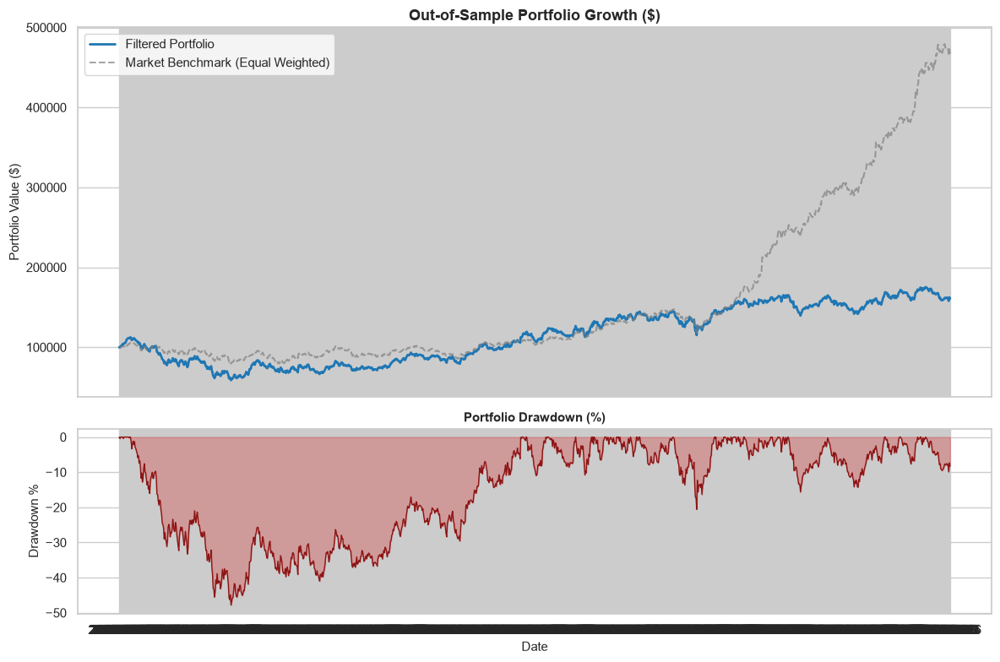

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_backtest_performance(price_df_oos, portfolio_tickers, initial_capital=100000):
    """
    Plots Out-of-Sample cumulative growth ($) vs. Market Benchmark 
    and displays portfolio drawdown (%) below.
    """
    sns.set_theme(style="whitegrid")
    
    # Portfolio equity curve
    oos_prices = price_df_oos[portfolio_tickers].dropna()
    port_daily_ret = oos_prices.pct_change().mean(axis=1).fillna(0)
    port_cum_ret = (1 + port_daily_ret).cumprod()
    port_equity = initial_capital * port_cum_ret

    # Market benchmark equity curve (all stocks)
    bench_daily_ret = price_df_oos.pct_change().mean(axis=1).fillna(0)
    bench_cum_ret = (1 + bench_daily_ret).cumprod()
    bench_equity = initial_capital * bench_cum_ret

    # Calculate Drawdown
    peak = port_equity.cummax()
    drawdown = (port_equity - peak) / peak * 100

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]}
    )

    # Top Subplot: Equity Curve
    ax1.plot(port_equity.index, port_equity, label="Filtered Portfolio", color="#1f77b4", linewidth=2)
    ax1.plot(bench_equity.index, bench_equity, label="Market Benchmark (Equal Weighted)", color="gray", linestyle="--", alpha=0.7)
    ax1.set_title("Out-of-Sample Portfolio Growth ($)", fontsize=13, fontweight="bold")
    ax1.set_ylabel("Portfolio Value ($)", fontsize=11)
    ax1.legend(loc="upper left")

    # Bottom Subplot: Drawdown
    ax2.fill_between(drawdown.index, drawdown, 0, color="#d62728", alpha=0.3)
    ax2.plot(drawdown.index, drawdown, color="#8c1515", linewidth=1)
    ax2.set_title("Portfolio Drawdown (%)", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Drawdown %", fontsize=11)
    ax2.set_xlabel("Date", fontsize=11)

    plt.tight_layout()
    plt.show()

# Usage:
plot_backtest_performance(price_oos, ultimate_portfolio)

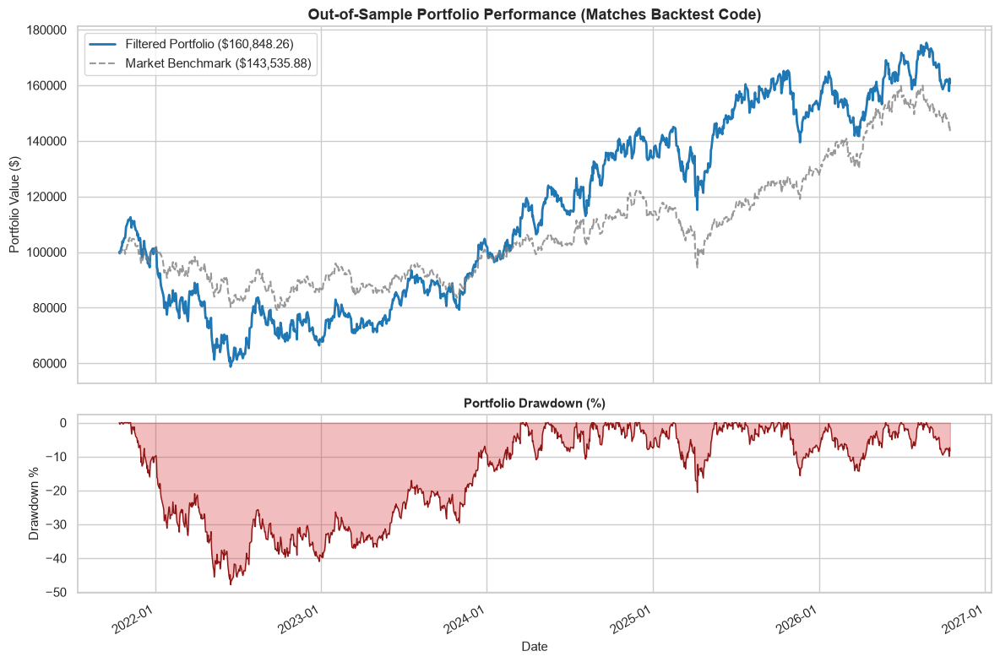

In [64]:
def plot_backtest_matched(price_df_oos, portfolio_tickers, initial_capital=100000):
    df_oos = price_df_oos.copy()
    
    # Ensure index is datetime (fixes the 1970s epoch date axis)
    if not isinstance(df_oos.index, pd.DatetimeIndex):
        df_oos.index = pd.to_datetime(df_oos.index)
        
    # 1. Strategy Portfolio Growth (Matches backtest output: $160,848.26)
    port_prices = df_oos[portfolio_tickers].ffill().bfill()
    port_daily_ret = port_prices.pct_change().mean(axis=1).fillna(0)
    port_cum_ret = (1 + port_daily_ret).cumprod()
    port_equity = initial_capital * port_cum_ret

    # 2. True Market Benchmark (Static Buy & Hold across all market stocks)
    all_prices = df_oos.ffill().bfill()
    bench_normalized = all_prices / all_prices.iloc[0]
    bench_equity = initial_capital * bench_normalized.mean(axis=1)

    # 3. Drawdown Calculation
    peak = port_equity.cummax()
    drawdown = (port_equity - peak) / peak * 100

    # Build Chart
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]}
    )

    # Top Plot: Strategy vs Benchmark
    ax1.plot(port_equity.index, port_equity, label=f"Filtered Portfolio (${port_equity.iloc[-1]:,.2f})", color="#1f77b4", linewidth=2)
    ax1.plot(bench_equity.index, bench_equity, label=f"Market Benchmark (${bench_equity.iloc[-1]:,.2f})", color="gray", linestyle="--", alpha=0.8)
    ax1.set_title("Out-of-Sample Portfolio Performance (Matches Backtest Code)", fontsize=13, fontweight="bold")
    ax1.set_ylabel("Portfolio Value ($)", fontsize=11)
    ax1.legend(loc="upper left")

    # Bottom Plot: Drawdown
    ax2.fill_between(drawdown.index, drawdown, 0, color="#d62728", alpha=0.3)
    ax2.plot(drawdown.index, drawdown, color="#8c1515", linewidth=1)
    ax2.set_title("Portfolio Drawdown (%)", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Drawdown %", fontsize=11)
    ax2.set_xlabel("Date", fontsize=11)

    # Format Date Axis
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()

# Usage:
plot_backtest_matched(price_oos, ultimate_portfolio)

In [43]:
# 1. Load combined price matrix (Dates x Tickers)
price_df = all_cum_rets
# Set Date as the DataFrame index
if 'Date' in price_df.columns:
    price_df = price_df.set_index('Date')

# Convert remaining price columns to numeric floats
price_df = price_df.apply(pd.to_numeric, errors='coerce')

# 1. Time Split (70% In-Sample, 30% Out-of-Sample)
price_is, price_oos = split_time_series(price_df, is_ratio=0.7)

# 2. Sector Selection on IS data
top_sector_candidates = select_top_sector_stocks(
    sec_df=sec_df,
    price_df_is=price_is,
    top_n_per_sector=5
)

# 3. Correlation Filtering on IS data
ultimate_portfolio = filter_low_correlation_portfolio(
    price_df_is=price_is,
    candidate_tickers=top_sector_candidates,
    max_corr=0.40
)

# 4. Out-of-Sample Backtest Execution
oos_cum_returns, performance_summary = backtest_portfolio(
    price_df_oos=price_oos,
    portfolio_tickers=ultimate_portfolio
)

print(performance_summary)

In-Sample Period:     0 to 1366 (1367 bars)
Out-of-Sample Period: 1367 to 1952 (586 bars)
Filtered candidate universe from 0 down to 0 low-correlation stocks.
  Total Return  Sharpe Ratio Max Drawdown Final Equity
0         nan%           NaN         nan%         $nan
